# Шаг 2. Тон и эмоции текста

Самая частая практическая задача с текстом — **классификация**: отнести текст к одному из классов.
Магазины сортируют так отзывы, банки — обращения клиентов, соцсети — комментарии.

Возьмём две готовые модели. Обе устроены одинаково: **тело** — rubert-tiny2 (29 млн весов, понимает русский текст),
**голова** — один слой `Linear`, как в сессиях 3–4. Их дообучили на размеченных текстах:

| Модель | Классы | На чём учили |
|--------|--------|--------------|
| `sentiment` | нейтрально, позитив, негатив | отзывы, посты в соцсетях, новости |
| `emotion` | без эмоций, радость, грусть, удивление, страх, злость | корпус CEDR — фразы из блогов, новостей и книг |

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

## 1. Классификатор в три строки: `pipeline`

В библиотеке `transformers` есть `pipeline` — «готовый конвейер»: текст на входе, ответ на выходе.
Внутри он делает всё сам: режет текст на токены, прогоняет через модель, превращает числа в вероятности.

In [2]:
import matplotlib.pyplot as plt
import torch

from common import load_model, load_tokenizer, model_dir, onegin_stanzas, load_onegin, show
from transformers import pipeline     # после common: там отключены лишние предупреждения

classify = pipeline("text-classification", model=str(model_dir("sentiment")), top_k=None)

RU = {"neutral": "нейтрально", "positive": "позитив", "negative": "негатив",
      "no_emotion": "без эмоций", "joy": "радость", "sadness": "грусть", "surprise": "удивление",
      "fear": "страх", "anger": "злость"}

for text in ["Отличный фильм, всем советую!", "Ужасное обслуживание, больше не приду.", "Магазин работает с 9 до 21."]:
    result = classify(text)[0]                 # список {"label", "score"} от самого вероятного
    print(f"{text:40s} → " + ", ".join(f"{RU[r['label']]} {r['score']:.0%}" for r in result))

Отличный фильм, всем советую!            → позитив 100%, нейтрально 0%, негатив 0%
Ужасное обслуживание, больше не приду.   → негатив 95%, нейтрально 4%, позитив 0%
Магазин работает с 9 до 21.              → нейтрально 61%, позитив 31%, негатив 8%


## 2. Что внутри конвейера

Сделаем то же самое руками — и увидим знакомые детали из сессий 3–5:

1. **Токенизатор** (шаг 1): текст → номера токенов, `[CLS]` в начале.
2. **BERT**: каждый токен → вектор из 312 чисел, которые «посмотрели» на все остальные токены (внимание из сессии 5).
3. **Pooler** — ещё один слой `Linear(312, 312)` с функцией tanh: «подготавливает» вектор токена `[CLS]` для классификации.
4. **Голова** `Linear(312, 3)`: выдаёт 3 «сырые оценки» (логиты).
5. **Softmax**: оценки → вероятности, в сумме 1.

In [3]:
tok = load_tokenizer("sentiment")
model = load_model("sentiment", "classifier")
print("голова модели:", model.classifier)

text = "Отличный фильм, всем советую!"
batch = tok(text, return_tensors="pt")
print("токены:", tok.convert_ids_to_tokens(batch["input_ids"][0]))
with torch.no_grad():
    hidden = model.bert(**batch).last_hidden_state      # (1, число токенов, 312)
    cls = hidden[:, 0]                                  # вектор токена [CLS], (1, 312)
    pooled = torch.tanh(model.bert.pooler.dense(cls))   # pooler: Linear + tanh
    logits = model.classifier(pooled)                   # голова, (1, 3)
probs = torch.softmax(logits, dim=-1)[0]
print("форма векторов после BERT:", tuple(hidden.shape))
print("логиты:", [round(x, 2) for x in logits[0].tolist()])
print("вероятности:", {RU[model.config.id2label[i]]: f"{p:.0%}" for i, p in enumerate(probs.tolist())})

голова модели:

 Linear(in_features=312, out_features=3, bias=True)
токены: ['[CLS]', 'Отличный', 'фильм', ',', 'всем', 'советую', '!', '[SEP]']
форма векторов после BERT: (1, 8, 312)
логиты: [-1.53, 4.18, -2.39]
вероятности: {'нейтрально': '0%', 'позитив': '100%', 'негатив': '0%'}


Вероятности совпали с `pipeline` — значит, внутри конвейера ровно эти шаги.

Обратите внимание: из 29 млн весов модели на саму «голову» приходится всего 312 × 3 + 3 = 939.
Всю тяжёлую работу — «понять текст» — делает тело, которое один раз обучили на огромном количестве текстов.
Этот же приём мы повторим сами в шаге 4.

## 3. Где модель ошибается

Модель хорошо справляется с прямыми словами («отличный», «ужасный»). А как насчёт сложных случаев?
Перед запуском попробуйте угадать, что ответит модель на каждую фразу.

In [4]:
tricky = [
    "Фильм хороший.",
    "Фильм не плохой.",                                   # отрицание
    "Не сказать, что фильм хороший.",                     # отрицание хорошего
    "Ну просто супер: опять дождь и опять пробки.",       # сарказм
    "Начало было скучным, но финал потрясающий!",         # смена тона
    "Ваще огонь 🔥🔥🔥",                                   # сленг и смайлики
    "Отлчный фльм, всем саветую",                         # опечатки
]


def sentiment_table(texts):
    for text in texts:
        result = {r["label"]: r["score"] for r in classify(text)[0]}
        best = max(result, key=result.get)
        print(f"{text:48s} → {RU[best]:10s} " + "  ".join(f"{RU[k][:3]} {result[k]:4.0%}" for k in ["positive", "neutral", "negative"]))


sentiment_table(tricky)

Фильм хороший.                                   → позитив    поз  88%  ней  11%  нег   0%
Фильм не плохой.                                 → нейтрально поз   2%  ней  84%  нег  14%
Не сказать, что фильм хороший.                   → нейтрально поз   8%  ней  85%  нег   7%
Ну просто супер: опять дождь и опять пробки.     → позитив    поз  89%  ней   9%  нег   2%
Начало было скучным, но финал потрясающий!       → позитив    поз  81%  ней  15%  нег   4%
Ваще огонь 🔥🔥🔥                                   → позитив    поз  89%  ней  11%  нег   1%
Отлчный фльм, всем саветую                       → позитив    поз  69%  ней  16%  нег  16%


**Обсудим:**
- с сарказмом модели тяжело — для этого нужно знать, что «опять дождь» — это плохо, а «супер» сказано с иронией;
- модель не «понимает» текст как человек: она нашла закономерности в размеченных примерах. Если похожих примеров не было — ошибается;
- опечатки меняют токены (шаг 1): «Отлчный» режется на незнакомые кусочки.

## 4. Эмоции: несколько ответов сразу

У тона ответ один (softmax: вероятности в сумме 1). А эмоций в тексте может быть **несколько**: «Я так рад, что мы победили,
но жалко, что лето кончилось». Поэтому у модели эмоций вместо softmax — **сигмоида** для каждого класса отдельно:
каждая эмоция получает свою вероятность от 0 до 1, и сумма может быть любой. Это называется multi-label — «много меток».

Какое счастье — наконец каникулы!                       радос 0.98


Мне грустно, что лето закончилось.                      груст 0.98
Неужели это правда? Не может быть!                      удивл 0.82
Мне очень страшно, я боюсь темноты.                     страх 0.94
Как же меня бесит этот шум!                             груст 0.22 злост 0.67
Я рад, что мы победили, но жаль, что лето кончилось.    радос 0.18 груст 0.93
Поезд отправляется в 10:15.                             без э 0.99
Ура, мы выиграли олимпиаду!                             без э 0.98
Сколько можно опаздывать?! Я жду уже час!               груст 0.79


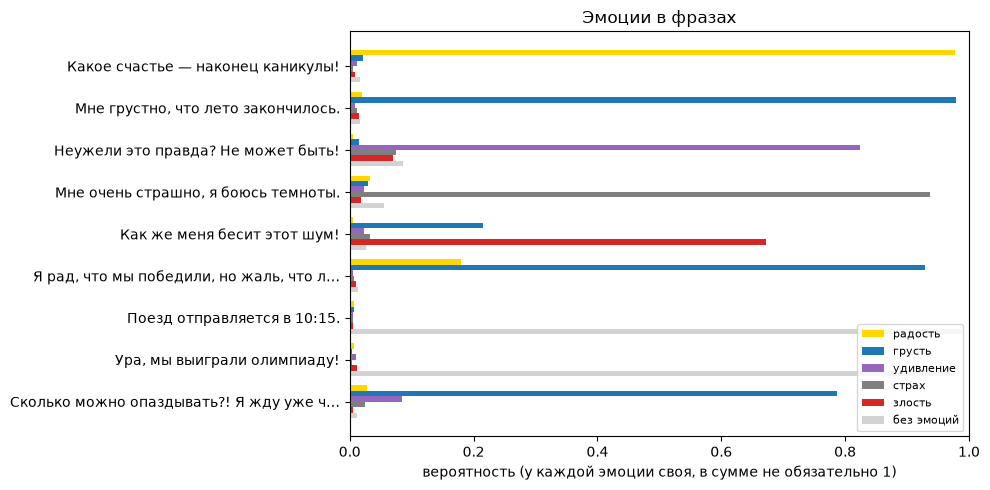

In [5]:
emotions = pipeline("text-classification", model=str(model_dir("emotion")), top_k=None)
EMO = ["joy", "sadness", "surprise", "fear", "anger", "no_emotion"]
COLORS = ["gold", "tab:blue", "tab:purple", "tab:gray", "tab:red", "lightgray"]

phrases = [
    "Какое счастье — наконец каникулы!",
    "Мне грустно, что лето закончилось.",
    "Неужели это правда? Не может быть!",
    "Мне очень страшно, я боюсь темноты.",
    "Как же меня бесит этот шум!",
    "Я рад, что мы победили, но жаль, что лето кончилось.",
    "Поезд отправляется в 10:15.",
    "Ура, мы выиграли олимпиаду!",
    "Сколько можно опаздывать?! Я жду уже час!",
]
table = []
for text in phrases:
    scores = {r["label"]: r["score"] for r in emotions(text)[0]}
    table.append([scores[e] for e in EMO])
    print(f"{text:55s} " + " ".join(f"{RU[e][:5]} {scores[e]:.2f}" for e in EMO if scores[e] > 0.15))

table = torch.tensor(table)
fig, ax = plt.subplots(figsize=(10, 5))
for j, (e, c) in enumerate(zip(EMO, COLORS)):
    ax.barh([i + (j - 2.5) * 0.13 for i in range(len(phrases))], table[:, j], height=0.13, color=c, label=RU[e])
ax.set_yticks(range(len(phrases)), [p if len(p) < 40 else p[:38] + "…" for p in phrases])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("вероятность (у каждой эмоции своя, в сумме не обязательно 1)")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Эмоции в фразах")
plt.tight_layout()
plt.savefig("emotions.png", dpi=100)
show()

Первые семь фраз модель разбирает уверенно, а в смешанной фразе находит и грусть, и (слабее) радость.
А вот последние две — ошибки: «Ура, мы выиграли олимпиаду!» — «без эмоций», а возмущение опозданием — «грусть».
Слова «рад», «счастье», «бесит» модель знает хорошо, а «ура» и «сколько можно» — видимо, редко встречала в обучающих текстах
с правильной меткой. Модель эмоций заметно слабее модели тона: эмоций больше, а размеченных примеров меньше
(в корпусе CEDR около 9 тысяч фраз).

## 5. Эмоциональная кардиограмма «Евгения Онегина»

Прогоним через модель **каждую строфу** романа и отметим на графике радость и грусть.
Чтобы линия не прыгала от строфы к строфе, усредним соседние строфы (скользящее среднее по 7 строфам).

Это ещё и проверка на «чужих» данных: модель учили на современных текстах из интернета, а здесь — стихи XIX века.

Строф: 377, глав: 8


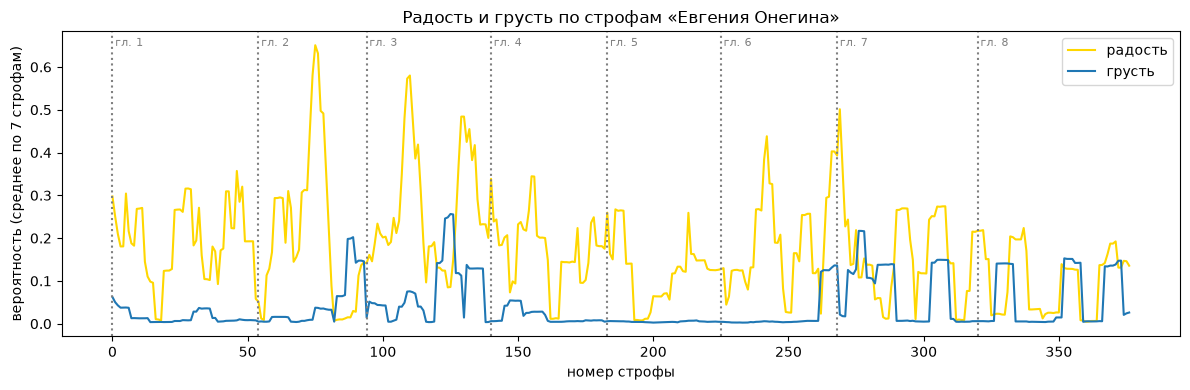


Самая радостная строфа по мнению модели (№ 255, 98%):
Приятно дерзкой эпиграммой
Взбесить оплошного врага;
Приятно зреть, как он, упрямо
Склонив бодливые рога,
Невольно в зеркало глядится
И узнавать себя стыдится;
Приятней, если он, друзья,
Завоет сдуру: это я!
Еще приятнее в молчанье
Ему готовить честный гроб
И тихо целить в бледный лоб
На благородном расстоянье;
Но отослать его к отцам
Едва ль приятно будет вам.

Самая грустная строфа по мнению модели (№ 355, 97%):
: И я лишен того: для вас
Тащусь повсюду наудачу;
Мне дорог день, мне дорог час:
А я в напрасной скуке трачу
Судьбой отсчитанные дни.
И так уж тягостны они.
Я знаю: век уж мой измерен;
Но чтоб продлилась жизнь моя,
Я утром должен быть уверен,
Что с вами днем увижусь я...


In [6]:
text = load_onegin()
stanzas, chapter_starts = [], []
for part in text.split("ГЛАВА")[1:]:                 # роман разбит на главы словом «ГЛАВА»
    chapter_starts.append(len(stanzas))
    stanzas += onegin_stanzas(part)
print(f"Строф: {len(stanzas)}, глав: {len(chapter_starts)}")

scores = []
for i in range(0, len(stanzas), 32):
    for result in emotions(stanzas[i:i + 32], truncation=True):
        s = {r["label"]: r["score"] for r in result}
        scores.append([s["joy"], s["sadness"]])
scores = torch.tensor(scores)


def smooth(x, k=7):
    """Скользящее среднее: каждая точка — среднее k соседних."""
    return torch.nn.functional.avg_pool1d(x.view(1, 1, -1), k, stride=1, padding=k // 2, count_include_pad=False).view(-1)


plt.figure(figsize=(12, 4))
plt.plot(smooth(scores[:, 0]), color="gold", label="радость")
plt.plot(smooth(scores[:, 1]), color="tab:blue", label="грусть")
for c, start in enumerate(chapter_starts):
    plt.axvline(start, color="gray", linestyle=":")
    plt.text(start + 1, plt.ylim()[1] * 0.95, f"гл. {c + 1}", fontsize=8, color="gray")
plt.xlabel("номер строфы")
plt.ylabel("вероятность (среднее по 7 строфам)")
plt.title("Радость и грусть по строфам «Евгения Онегина»")
plt.legend()
plt.tight_layout()
plt.savefig("onegin_emotions.png", dpi=100)
show()

for label, col in [("радостная", 0), ("грустная", 1)]:
    i = scores[:, col].argmax().item()
    print(f"\nСамая {label} строфа по мнению модели (№ {i}, {scores[i, col]:.0%}):\n{stanzas[i]}")

Посмотрите на самые «радостную» и «грустную» строфы. Согласны ли вы с моделью?

Самая «радостная» строфа — из главы 6, перед дуэлью: о том, как «приятно» готовить врагу «честный гроб».
Модель увидела пять раз слово «приятно» и решила, что это радость, а иронию Пушкина не поняла. Это та же ошибка,
что с сарказмом в пункте 3: модель опирается на отдельные слова больше, чем на смысл целого.

Где на графике письмо Татьяны (глава 3), дуэль и смерть Ленского (глава 6), последнее объяснение Онегина и Татьяны (глава 8)?

## Попробуйте сами

1. Придумайте три фразы, на которых модель тона ошибается. Что у них общего?
2. Найдите фразу, которую модель эмоций относит сразу к двум эмоциям с вероятностью больше 50%.
3. Поменяйте одно слово в фразе так, чтобы тон сменился с позитивного на негативный. Какое самое маленькое изменение для этого нужно?
4. Прогоните через модель тона отзыв о фильме или игре из интернета. Совпадает ли ответ с оценкой автора отзыва?
5. В пункте 5 замените радость и грусть на страх и злость. В какой главе больше всего страха?